# Solar irradiance

This tutorial compares the extraterrestrial solar irradiance spectra of the package, shows how they
are seen by sensors of different spectral resolutions, and computes the solar irradiance at the top
and bottom of the atmosphere.

The plane solar irradiance at the top of the atmosphere is (Eq. {eq}`e0` of the {doc}`../methods`
page)

$$
E_0(\lambda) = \mu_0\, d^{2}(J)\, F_0(\lambda),
$$

with $F_0$ the extraterrestrial solar irradiance at mean Earth-Sun distance, $\mu_0 = \cos\theta_s$ and
$d^2(J)$ the Earth-Sun distance correction for the day of year $J$
({py:meth}`Misc.earth_sun_correction <radcalnet_oc.kernel.Misc.earth_sun_correction>`, Eq. {eq}`earth_sun`).

In [1]:
import logging

import matplotlib as mpl
import matplotlib.pyplot as plt
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
plt.rcParams.update({'font.size': 18, 'axes.labelsize': 22})
# no warning when the Times New Roman font is not installed
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import numpy as np
import xarray as xr

import radcalnet_oc as radoc
# radcalnet_oc sets the root logger to INFO: show only the warnings in this tutorial
logging.getLogger().setLevel(logging.WARNING)
print(f'radcalnet_oc: {radoc.__version__}')

radcalnet_oc: 1.1.0


## Extraterrestrial solar irradiance

{py:class}`~radcalnet_oc.lut.SolarIrradiance` loads four reference spectra, in mW m$^{-2}$ nm$^{-1}$:

- TSIS-1 hybrid solar reference spectrum (Coddington et al., 2021), recommended and used by default
  by {py:class}`~radcalnet_oc.process.Process`;
- Thuillier et al. (2003);
- Gueymard (2004);
- Kurucz (1992).

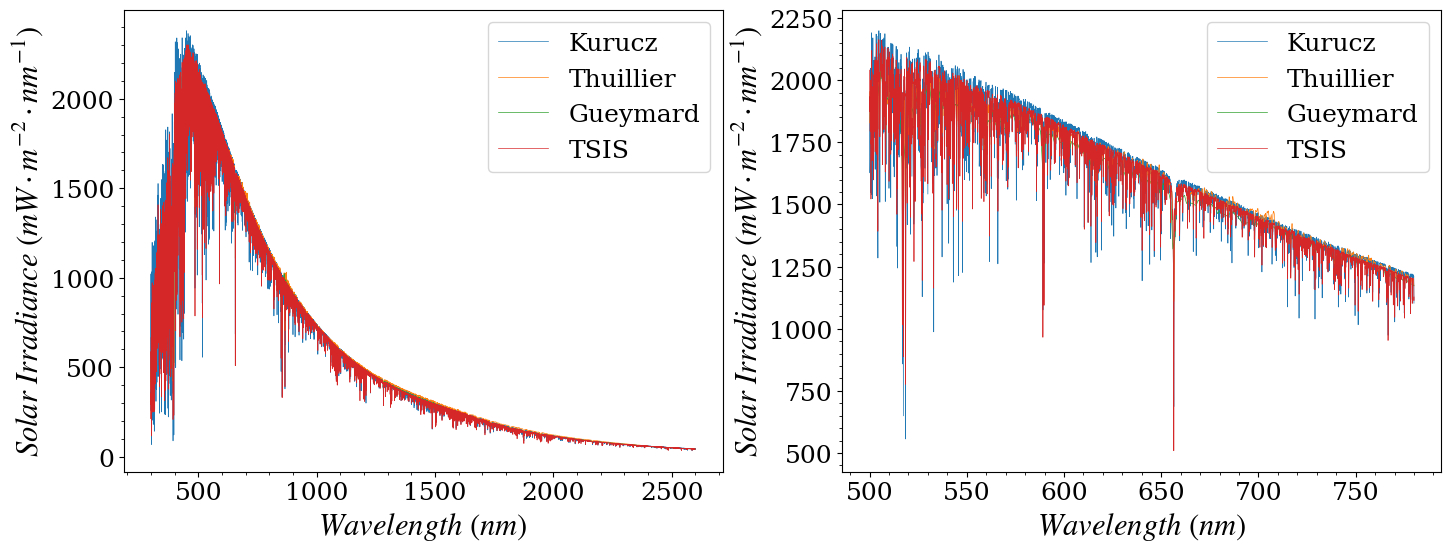

In [2]:
solar_irr=radoc.SolarIrradiance()
fig,axs = plt.subplots(1,2,figsize=(17,6))

solar_irr.kurucz.plot(lw=0.5,ax=axs[0],label='Kurucz')
solar_irr.thuillier.plot(lw=0.5,ax=axs[0],label='Thuillier')
solar_irr.gueymard.plot(lw=0.5,ax=axs[0],label='Gueymard')
solar_irr.tsis.plot(lw=0.5,ax=axs[0],label='TSIS')

axs[0].legend()

wl_range=slice(500,780)
solar_irr.kurucz.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Kurucz')
solar_irr.thuillier.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Thuillier')
solar_irr.gueymard.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Gueymard')
solar_irr.tsis.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='TSIS')
axs[1].legend()

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on()
    #ax.semilogy()

## Impact of the spectral resolution of the sensor

The spectra are convolved with Gaussian spectral responses of increasing full width at half maximum
`fwhm` (nm), centred on the central wavelengths `central_wl`, with
{py:meth}`Spectral.convolve <radcalnet_oc.lut.Spectral.convolve>` (Eq. {eq}`convolution`, see
{ref}`spectral_convolution`). The Fraunhofer lines are smoothed out as the bands get wider.

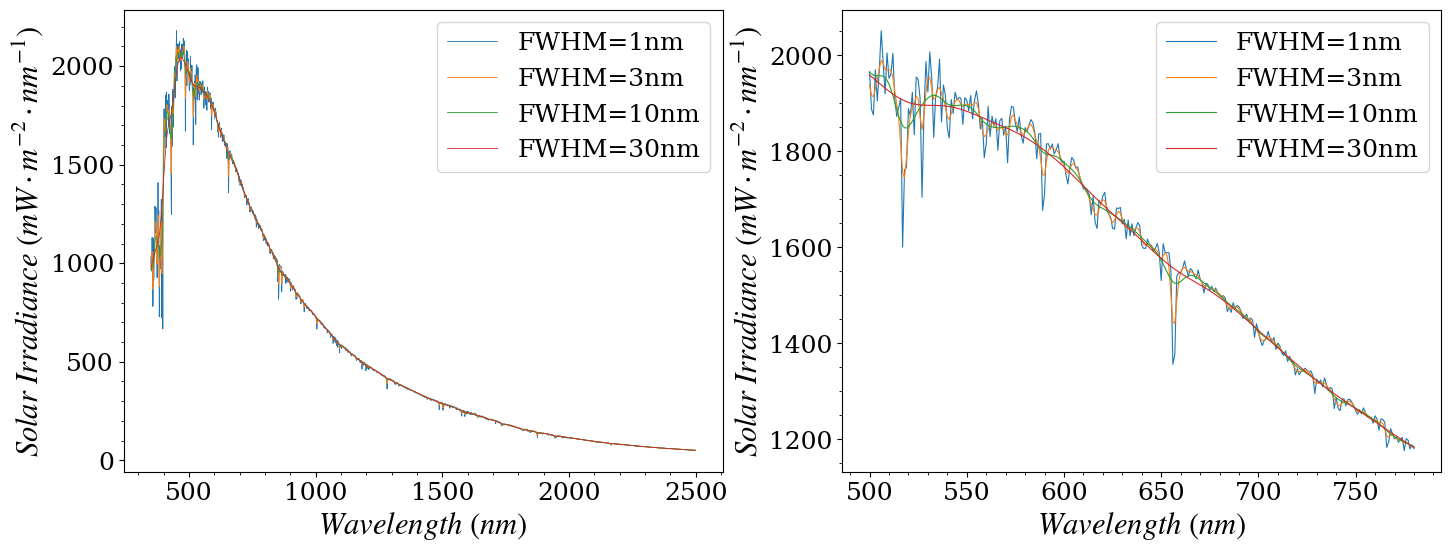

In [3]:
spectral_res=1
central_wl=np.arange(350,2500,spectral_res)

signal = solar_irr.tsis
wl_signal = solar_irr.tsis.wl.values

fig,axs = plt.subplots(1,2,figsize=(17,6))
wl_range=slice(500,780)
for fwhm in [1,3,10,30]:    
    spectral=radoc.Spectral(central_wl,fwhm)
    F0 = spectral.convolve(signal)
    F0.plot(lw=0.6,label='FWHM='+str(fwhm)+'nm',ax=axs[0])
    F0.sel(wl=wl_range).plot(lw=0.8,label='FWHM='+str(fwhm)+'nm',ax=axs[1])

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on()  
    ax.legend()

## Irradiance at the top and bottom of the atmosphere

The downwelling plane irradiance at the surface is (Eq. {eq}`ed`)

$$
E_d(\lambda) = T^{\downarrow}(\lambda, \theta_s, \tau_a)\; T_g^{E_d}(\lambda)\; E_0(\lambda),
$$

with $T^{\downarrow}$ the total (direct + diffuse) irradiance transmittance of the Rayleigh-aerosol
atmosphere, read in the transmittance look-up table for the solar zenith angle and the aerosol optical
thickness at 550 nm `aot550` (default aerosol models of `config.yml`), and $T_g^{E_d}$ the gaseous
transmittance of the irradiance. Since version 1.1, $T_g^{E_d}$ accounts for the coupling of the absorption
with the scattering: the diffuse light reaching the surface travels longer paths than the direct beam,
which is described by the photon path-length model in the O$_2$ and H$_2$O bands of 684-990 nm
({ref}`methods-gas-coupling`); elsewhere, it is the transmittance of the direct solar path (air mass
$1/\mu_0$, see the {doc}`radcalnet_oc_gaseous_transmittance` tutorial). The irradiance is computed at mean Earth-Sun distance ($d^2 = 1$).

Atmospheric and geometric parameters:

In [4]:
# set Sun zenith angle 
sza=45
# set aerosol optical thickness
aot550=0.1
# tcwv cm into kg.m-2
tpw_cm=2.6
tcwv=tpw_cm*10 

to3_du=300 
pressure=1000

# conversion O3 du to kg.m-2
tco3=to3_du *2.14485e-5
tcno2=3e-6/100
tcch4= 1e-2

Look-up tables, prepared for the solar zenith angle:

In [5]:
from radcalnet_oc.kernel import GasCoupling, GAS_COUPLING_PPLD_FILE

lut = radoc.LUT(wl=np.arange(350, 2500, 1))
lut.load_auxiliary_data()
lut.lut_preparation(sza=[sza])
gas_trans = radoc.GaseousTransmittance(lut.gas_lut)   # line-by-line O2 by default (o2_model='lbl')
gas_trans.pressure = pressure
gas_trans.gas_tc['h2o'] = tcwv
gas_trans.gas_tc['o3'] = tco3
gas_trans.gas_tc['no2'] = tcno2
gas_trans.gas_tc['ch4'] = tcch4

$E_0$ and $E_d$ for Gaussian spectral responses of 1, 3 and 10 nm FWHM:

 364. 365.] nm truncated by the wavelength range of the signal (349.926-2599.77 nm)


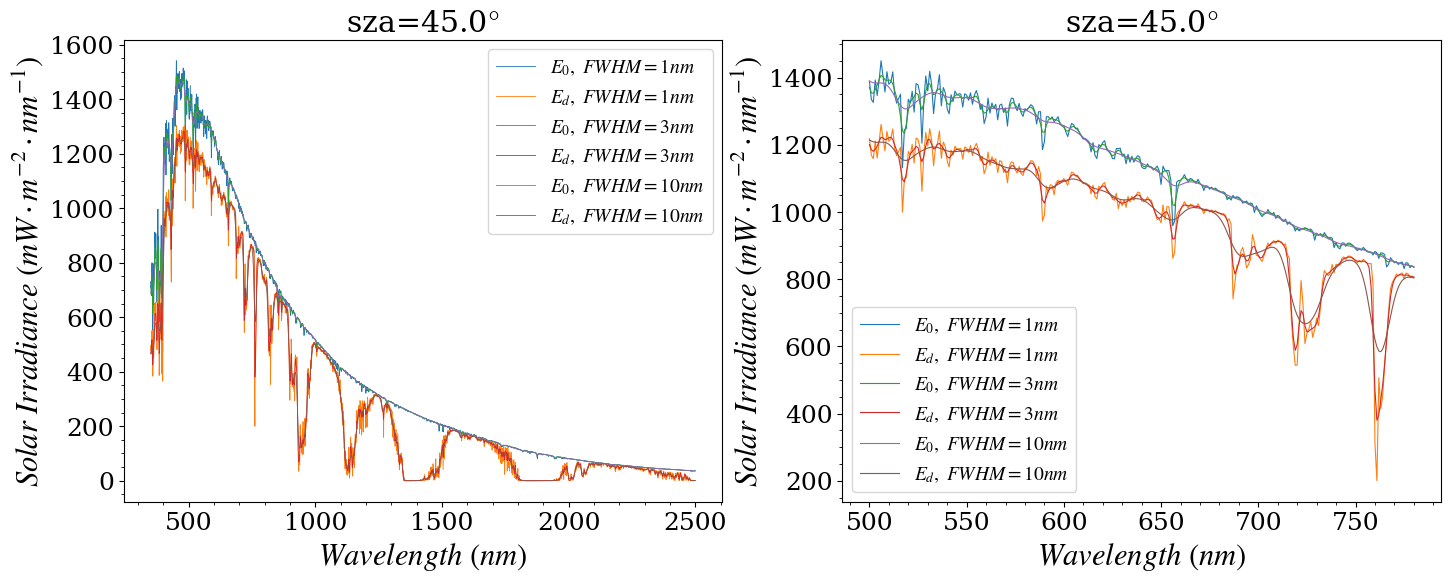

In [6]:
solar_irr = radoc.SolarIrradiance()
mu0 = np.cos(np.radians(sza))
central_wl = np.arange(350, 2500, 1)
wl_range = slice(500, 780)

# total (direct + diffuse) irradiance transmittance of the Rayleigh-aerosol atmosphere
Taero_mol = (lut.trans_Ed.squeeze(drop=True).interp(aot_ref=aot550)
             .interp(wl=central_wl, method='quadratic').reset_coords(drop=True))

# gaseous transmittance of the irradiance, coupled with the scattering (photon path-length model)
coupling = GasCoupling(GAS_COUPLING_PPLD_FILE)
Tg_Ed = gas_trans.get_coupled_transmittance(1. / mu0, 'Ed', aot550, coupling)

fig, axs = plt.subplots(1, 2, figsize=(17, 6))
for fwhm in [1, 3, 10]:
    spectral = radoc.Spectral(central_wl, fwhm)
    F0 = spectral.convolve(solar_irr.tsis) * mu0
    Tg = spectral.convolve(Tg_Ed)
    F0.plot(lw=0.6, label=r'$E_{0},\ FWHM=' + str(fwhm) + r'nm$', ax=axs[0])
    F0.sel(wl=wl_range).plot(lw=0.8, label=r'$E_{0},\ FWHM=' + str(fwhm) + r'nm$', ax=axs[1])
    Ed = Taero_mol * F0 * Tg
    Ed.plot(lw=0.6, label=r'$E_{d},\ FWHM=' + str(fwhm) + r'nm$', ax=axs[0])
    Ed.sel(wl=wl_range).plot(lw=0.8, label=r'$E_{d},\ FWHM=' + str(fwhm) + r'nm$', ax=axs[1])
for ax in axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on()
    ax.set_title('sza={:.1f}'.format(sza) + r'$\degree$')
    ax.legend(fontsize=14)